#### Bước đầu: INPUT TỪ DATASET ĐÃ KHÁM PHÁ PHÂN TÍCH (Amazon_clean.csv)

In [46]:
#trên Vscode
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('../data/processed/Amazon_clean.csv',low_memory=False)

'''
TRÊN COLAB 
từ link gg drive ta cắt phần file_id cần thiết https://drive.google.com/file/d/1gmLHX7TZ8hrkdqLKHztOFN29_4etvI4A/view?usp=sharing
ta có file_id: 1gmLHX7TZ8hrkdqLKHztOFN29_4etvI4A
'''
# import gdown
# import pandas as pd
# import matplotlib.pyplot as plt
# file_id = "1gmLHX7TZ8hrkdqLKHztOFN29_4etvI4A"  # Thay bằng ID file CSV của bạn
# url = f"https://drive.google.com/uc?id={file_id}"
# output = "Amazon_clean.csv"
# gdown.download(url, output, quiet=False)
# df = pd.read_csv(output)


df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['IsValid'] = ~df['OrderStatus'].isin(['Cancelled', 'Returned'])
df['Year'] = df['OrderDate'].dt.year
df['Month'] = df['OrderDate'].dt.month
print('read thành công')

read thành công


In [47]:
#dataset có bao nhiêu mục, cột dòng
print(df.shape)

(100000, 23)


In [48]:
#thông tin data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   OrderID        100000 non-null  str           
 1   OrderDate      100000 non-null  datetime64[us]
 2   CustomerID     100000 non-null  str           
 3   CustomerName   100000 non-null  str           
 4   ProductID      100000 non-null  str           
 5   ProductName    100000 non-null  str           
 6   Category       100000 non-null  str           
 7   Brand          100000 non-null  str           
 8   Quantity       100000 non-null  int64         
 9   UnitPrice      100000 non-null  float64       
 10  Discount       100000 non-null  float64       
 11  Tax            100000 non-null  float64       
 12  ShippingCost   100000 non-null  float64       
 13  TotalAmount    100000 non-null  float64       
 14  PaymentMethod  100000 non-null  str           
 15  OrderStatus 

In [49]:
df.head()

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,...,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID,IsValid,Year,Month
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,...,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967,True,2023,1
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,...,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298,True,2023,12
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,...,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908,True,2022,5
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,...,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164,True,2023,7
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.64,...,821.36,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411,False,2023,2


In [50]:
df.tail()

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,...,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID,IsValid,Year,Month
99995,ORD0099996,2023-03-07,CUST001356,Karan Joshi,P00047,Memory Card 128GB,Electronics,Apex,2,492.34,...,1066.20,UPI,Delivered,Jacksonville,FL,India,SELL00041,True,2023,3
99996,ORD0099997,2021-11-24,CUST031254,Sunita Kapoor,P00046,Car Charger,Sports & Outdoors,Apex,5,449.30,...,2432.29,Credit Card,Delivered,San Jose,CA,United States,SELL01449,True,2021,11
99997,ORD0099998,2023-04-29,CUST012579,Aman Gupta,P00030,Dress Shirt,Sports & Outdoors,BrightLux,4,232.40,...,1016.40,Cash on Delivery,Delivered,Indianapolis,IN,United States,SELL00028,True,2023,4
99998,ORD0099999,2021-11-01,CUST026243,Simran Gupta,P00046,Car Charger,Sports & Outdoors,HomeEase,1,294.05,...,330.66,Debit Card,Delivered,Charlotte,NC,United States,SELL00324,True,2021,11
99999,ORD0100000,2021-12-04,CUST029492,Sunita Reddy,P00019,LED Desk Lamp,Home & Kitchen,CoreTech,5,166.70,...,858.52,Debit Card,Delivered,New York,NY,United States,SELL00761,True,2021,12


### CÂU 1: TÍNH TOÁN CÁC CHỈ SỐ KPI

Hà Mạnh Trí

In [51]:
#Chuẩn bị dữ liệu
# Lấy các cột cần thiết
df_kpi = df[['OrderID', 'TotalAmount',
             'ShippingCost', 'OrderStatus']].copy()

# Chuyển dữ liệu tiền tệ về dạng số
df_kpi['TotalAmount'] = pd.to_numeric(
    df_kpi['TotalAmount'], errors='coerce'
)

df_kpi['ShippingCost'] = pd.to_numeric(
    df_kpi['ShippingCost'], errors='coerce'
)

print("Tổng số dòng:", len(df_kpi))
print("Số đơn hàng:", df_kpi['OrderID'].nunique())

Tổng số dòng: 100000
Số đơn hàng: 100000


In [52]:
# Tính KPI
# Tổng số đơn hàng
total_orders = df_kpi['OrderID'].nunique()

# Loại bỏ đơn hủy và đơn trả
df_revenue = df_kpi[
    ~df_kpi['OrderStatus'].isin(
        ['Cancelled', 'Returned']
    )
].copy()

# Tổng doanh thu hợp lệ
total_revenue = df_revenue['TotalAmount'].sum()

# Tổng phí vận chuyển
total_shipping = df_kpi['ShippingCost'].sum()

print("===== KPI TỔNG QUAN =====")
print(f"Tổng đơn hàng: {total_orders:,}")
print(f"Tổng doanh thu: {total_revenue:,.2f}")
print(f"Tổng phí vận chuyển: {total_shipping:,.2f}")

===== KPI TỔNG QUAN =====
Tổng đơn hàng: 100,000
Tổng doanh thu: 86,193,863.07
Tổng phí vận chuyển: 740,666.01


In [53]:
# Tỷ lệ trạng thái đơn hàng
status_count = df_kpi['OrderStatus'].value_counts()

status_percent = (
    status_count / total_orders * 100
).round(2)

status_summary = pd.DataFrame({
    'Số lượng đơn': status_count,
    'Tỷ lệ (%)': status_percent
})

display(status_summary)

,Số lượng đơn,Tỷ lệ (%)
OrderStatus,,
Delivered,74628,74.63
Shipped,15192,15.19
Pending,4103,4.10
Returned,3049,3.05
Cancelled,3028,3.03


### CÂU 2 DOANH THU VÀ SỐ ĐƠN THEO THÁNG, NĂM

Lâm Gia Lạc

In [54]:
print(df.shape)
df[['OrderDate', 'Year', 'Month', 'TotalAmount', 'OrderStatus']].head()

(100000, 23)


,OrderDate,Year,Month,TotalAmount,OrderStatus
0,2023-01-31,2023,1,319.86,Delivered
1,2023-12-30,2023,12,259.64,Delivered
2,2022-05-10,2022,5,108.06,Delivered
3,2023-07-18,2023,7,159.66,Delivered
4,2023-02-04,2023,2,821.36,Cancelled


In [55]:
# Doanh thu: chỉ tính đơn không bị hủy hoặc trả
valid = ~df['OrderStatus'].isin(['Cancelled', 'Returned'])
df['Revenue'] = df['TotalAmount'].where(valid, 0)

# Tổng hợp theo năm
yearly = (df.groupby('Year')
            .agg(Orders=('OrderID', 'count'), Revenue=('Revenue', 'sum')))
yearly['Revenue'] = yearly['Revenue'] / 1e6   # đơn vị: triệu

# Tổng hợp theo năm và tháng
monthly = (df.groupby(['Year', 'Month'])
             .agg(Orders=('OrderID', 'count'), Revenue=('Revenue', 'sum'))
             .reset_index())
monthly['Revenue'] = monthly['Revenue'] / 1e6
yearly
month_avg = monthly.groupby('Month').agg(Orders=('Orders', 'mean'), Revenue=('Revenue', 'mean'))
month_avg

,Orders,Revenue
Month,,
1,1727.6,1.484446
2,1523.6,1.306827
3,1687.6,1.451074
4,1642.0,1.430984
5,1711.8,1.475460
6,1662.4,1.440817
7,1687.4,1.460190
8,1733.6,1.478939
9,1655.2,1.419377


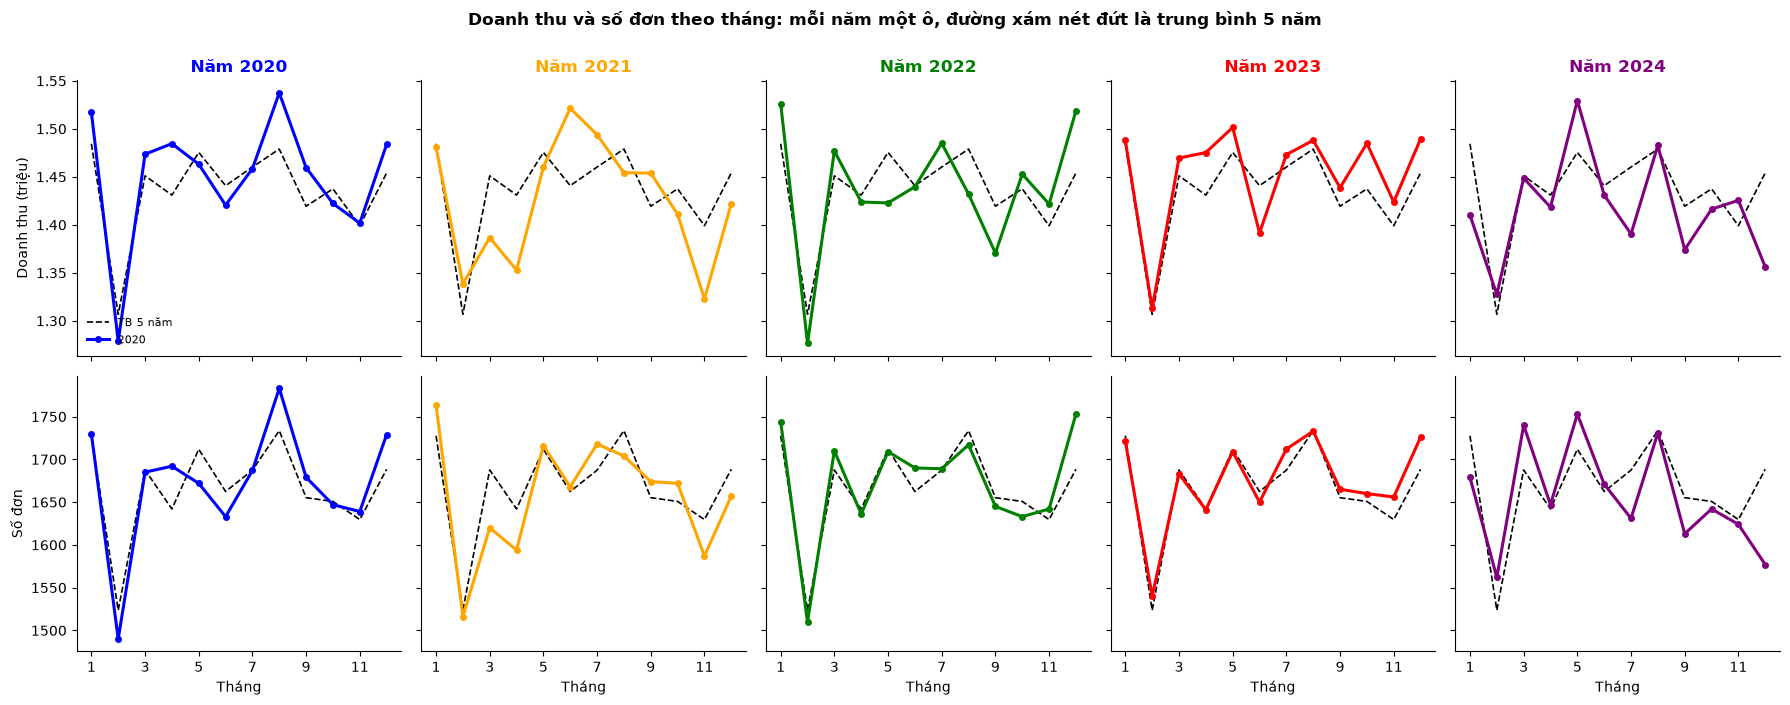

In [56]:
# Biểu đồ 1: small multiples, mỗi năm một ô, cùng thang đo để so sánh dễ hơn
YEAR_COLORS = ['blue', 'orange', 'green', 'red', 'purple']
years = sorted(monthly['Year'].unique())
rows = [
    ('Revenue', 'Doanh thu (triệu)', 'Doanh thu theo tháng từng năm'),
    ('Orders', 'Số đơn', 'Số đơn theo tháng từng năm'),
]
fig, axes = plt.subplots(2, len(years), figsize=(18, 7), sharex=True, sharey='row')

for r, (col, ylabel, row_title) in enumerate(rows):
    for c, (year, color) in enumerate(zip(years, YEAR_COLORS)):
        ax = axes[r, c]
        s = monthly[monthly['Year'] == year]
        ax.plot(month_avg.index, month_avg[col], color='black', lw=1.2, ls='--', label='TB 5 năm')
        ax.plot(s['Month'], s[col], color=color, lw=2.2, marker='o', ms=4, label=str(year))
        ax.set_xticks(range(1, 13, 2))
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(False)
        if r == 0:
            ax.set_title(f'Năm {year}', fontweight='bold', color=color)
        if r == len(rows) - 1:
            ax.set_xlabel('Tháng')
        if c == 0:
            ax.set_ylabel(ylabel)

axes[0, 0].legend(frameon=False, fontsize=8, loc='lower left')
fig.suptitle('Doanh thu và số đơn theo tháng: mỗi năm một ô, đường xám nét đứt là trung bình 5 năm',
             fontweight='bold', fontsize=12, y=1.0)
plt.tight_layout()
plt.show()

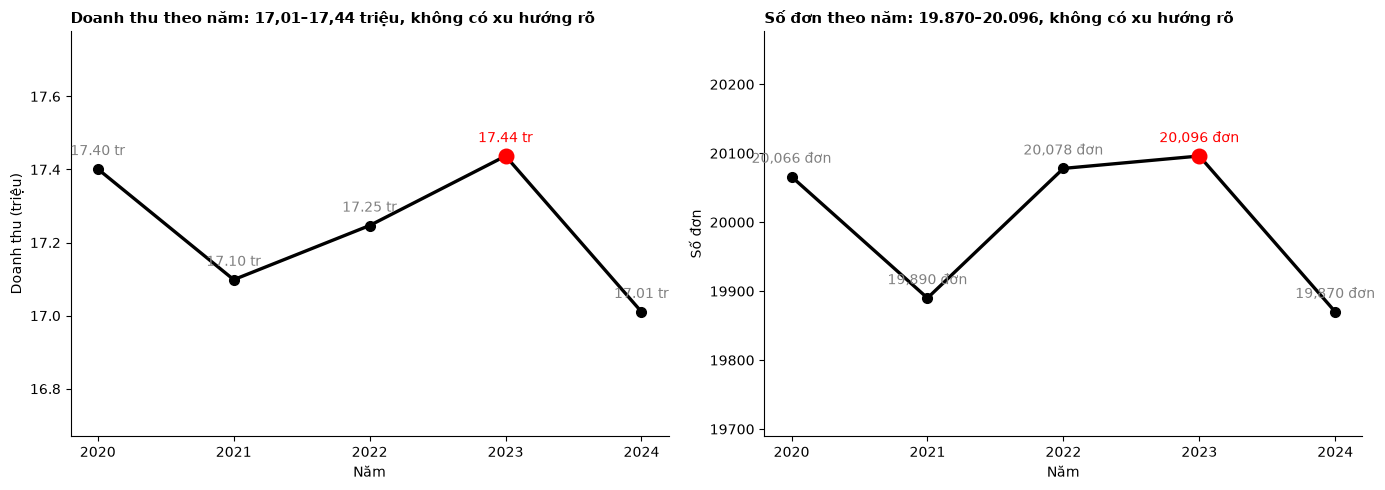

In [57]:
# Biểu đồ 2: doanh thu và số đơn theo năm (mỗi chỉ số một đường riêng)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
specs = [
    (axes[0], 'Revenue', 'Doanh thu (triệu)', lambda v: f'{v:.2f} tr',
     'Doanh thu theo năm: 17,01–17,44 triệu, không có xu hướng rõ'),
    (axes[1], 'Orders', 'Số đơn', lambda v: f'{v:,.0f} đơn',
     'Số đơn theo năm: 19.870–20.096, không có xu hướng rõ'),
]
for ax, col, ylabel, fmt, title in specs:
    ax.plot(yearly.index, yearly[col], color='black', lw=2.4, marker='o', ms=7)
    peak = yearly[col].idxmax()
    ax.scatter([peak], [yearly.loc[peak, col]], s=110, color='red', zorder=5)
    for year, val in yearly[col].items():
        ax.annotate(fmt(val), xy=(year, val), xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=10, color='red' if year == peak else 'grey')
    ax.set_xticks(yearly.index)
    ax.set_xlabel('Năm')
    ax.set_ylabel(ylabel)
    margin = (yearly[col].max() - yearly[col].min()) * 0.8
    ax.set_ylim(yearly[col].min() - margin, yearly[col].max() + margin)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(title, loc='left', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

### CÂU 3: PHÂN TÍCH CƠ CẤU TRẠNG THÁI ĐƠN HÀNG

Hà Mạnh Trí

In [58]:
# Thống kê số lượng và tỷ lệ
# Đếm số đơn theo trạng thái
status_count = df_kpi['OrderStatus'].value_counts()

# Tính tỷ lệ phần trăm
status_percent = (
    status_count / status_count.sum() * 100
)

# Tạo bảng thống kê
status_summary = pd.DataFrame({
    'Số lượng đơn hàng': status_count,
    'Tỷ lệ (%)': status_percent.round(2)
})

display(status_summary)

,Số lượng đơn hàng,Tỷ lệ (%)
OrderStatus,,
Delivered,74628,74.63
Shipped,15192,15.19
Pending,4103,4.10
Returned,3049,3.05
Cancelled,3028,3.03


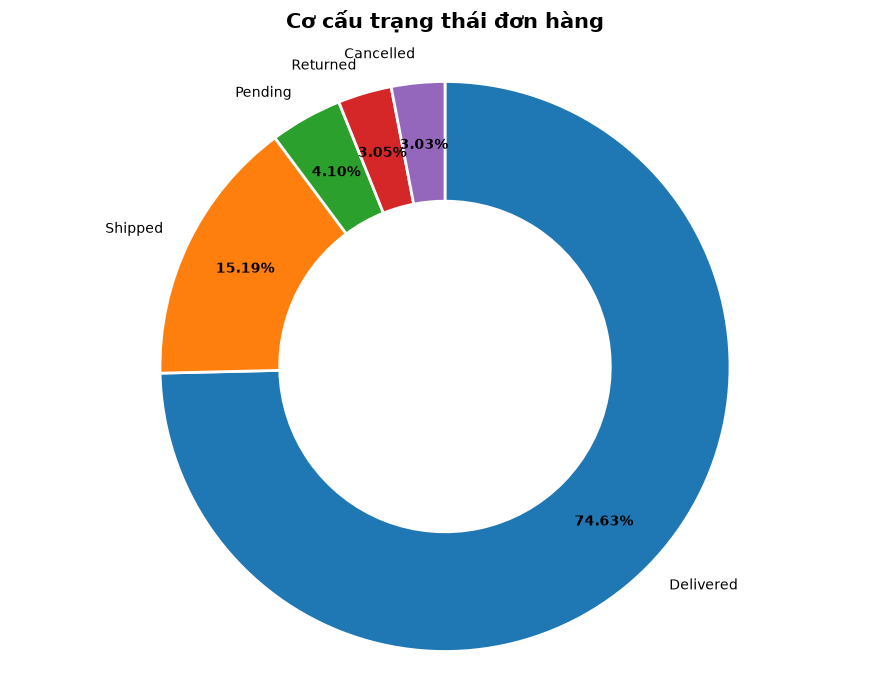

In [59]:
#Vẽ biểu đồ Donut Chart
plt.figure(figsize=(9, 7))

wedges, texts, autotexts = plt.pie(
    status_count.values,
    labels=status_count.index,
    autopct='%1.2f%%',
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    wedgeprops={
        'width': 0.42,
        'edgecolor': 'white',
        'linewidth': 2
    }
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

plt.title(
    'Cơ cấu trạng thái đơn hàng',
    fontsize=15,
    fontweight='bold',
    pad=18
)

plt.axis('equal')
plt.tight_layout()
plt.show()

In [60]:
# Xác định insight
status_summary = status_summary.sort_values(
    'Tỷ lệ (%)', ascending=False
)

print("Tổng số đơn:", status_count.sum())

print(
    "Trạng thái cao nhất:",
    status_summary.index[0],
    status_summary.iloc[0]['Tỷ lệ (%)'], "%"
)

print(
    "Trạng thái thấp nhất:",
    status_summary.index[-1],
    status_summary.iloc[-1]['Tỷ lệ (%)'], "%"
)

display(status_summary)

Tổng số đơn: 100000
Trạng thái cao nhất: Delivered 74.63 %
Trạng thái thấp nhất: Cancelled 3.03 %


,Số lượng đơn hàng,Tỷ lệ (%)
OrderStatus,,
Delivered,74628,74.63
Shipped,15192,15.19
Pending,4103,4.10
Returned,3049,3.05
Cancelled,3028,3.03


### CÂU 4: DOANH THU 10 NHÓM CAO NHẤT

Đặng Vũ Khoa

In [83]:
#Tính tổng doanh thu theo từng nhóm sản phẩm
doanh_thu_nhom = (df.groupby('Category')['TotalAmount'].sum())

#Sắp xếp để nhóm có doanh thu cao nhất nằm trên cùng
doanh_thu_nhom = doanh_thu_nhom.sort_values(ascending=True)
doanh_thu_nhom_top10 = doanh_thu_nhom.head(10)  # Lấy 10 nhóm sản phẩm có doanh thu cao nhất
print(doanh_thu_nhom_top10)


Category
Home & Kitchen       15163939.36
Toys & Games         15216684.99
Clothing             15253397.50
Books                15261837.01
Sports & Outdoors    15345571.88
Electronics          15584217.18
Name: TotalAmount, dtype: float64


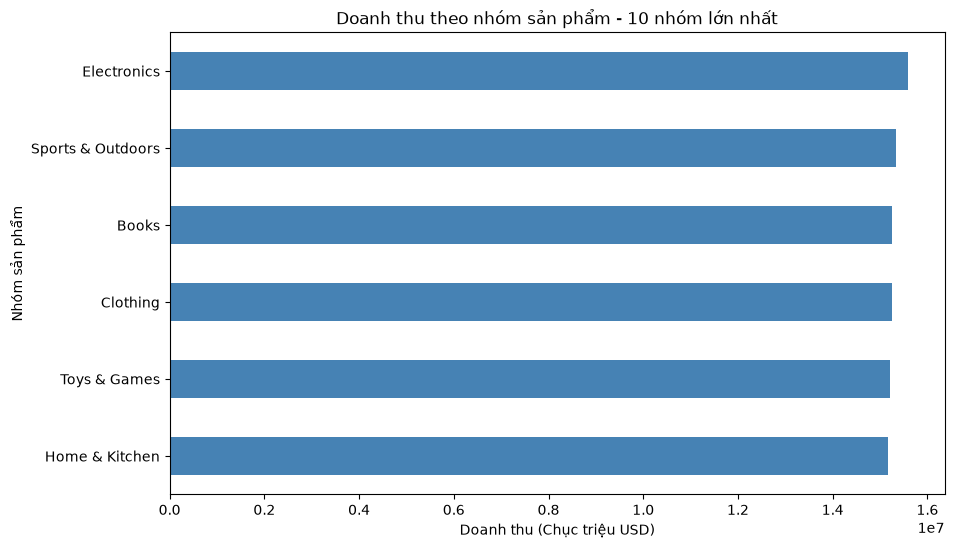

In [93]:
#Vẽ biểu đồ cột ngang bằng pandas plot()
doanh_thu_nhom_top10.plot(kind='barh', figsize=(10, 6), color='steelblue')

plt.title('Doanh thu theo nhóm sản phẩm - 10 nhóm lớn nhất')
plt.xlabel('Doanh thu (Chục triệu USD)')
plt.ylabel('Nhóm sản phẩm')
plt.show()

Doanh thu thực tế

In [64]:
# Dataframe doanh thu thực tế phải loại bỏ đơn Returned và Cancelled:

df_doanh_thu_thuc_te = df[
    df['OrderStatus'].isin([
        'Delivered',
        'Shipped',
        'Pending'
    ])
].copy() #tạo bản sao của dữ liệu đac lọc, không ảnh hương df gốc

doanh_thu_nhom = (df_doanh_thu_thuc_te.groupby('Category')['TotalAmount'].sum().sort_values(ascending=True))
print(doanh_thu_nhom)

Category
Home & Kitchen       14179805.98
Toys & Games         14253320.19
Books                14330308.82
Clothing             14332689.92
Sports & Outdoors    14434124.78
Electronics          14663613.38
Name: TotalAmount, dtype: float64


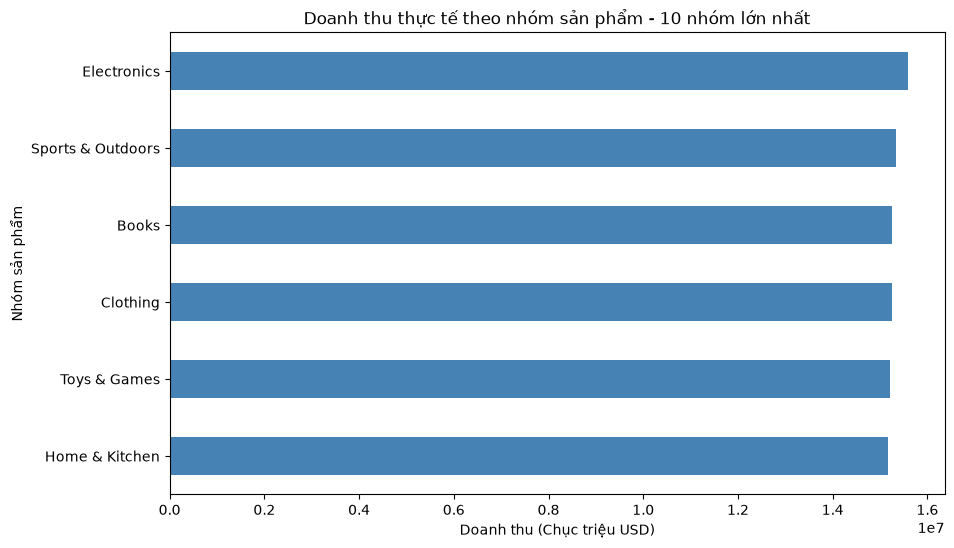

In [92]:
doanh_thu_nhom_top10 = doanh_thu_nhom.head(10)  # Lấy 10 nhóm sản phẩm có doanh thu cao nhất

#Vẽ biểu đồ cột ngang bằng pandas plot()
doanh_thu_nhom_top10.plot(kind='barh', figsize=(10, 6), color='steelblue')

plt.title('Doanh thu thực tế theo nhóm sản phẩm - 10 nhóm lớn nhất')
plt.xlabel('Doanh thu (Chục triệu USD)')
plt.ylabel('Nhóm sản phẩm')
plt.show()

### CÂU 5 : DOANH THU THEO KHU VỰC KHÁCH HÀNG

Lê Nguyễn Hoàng Sang

In [66]:

# Lọc đơn hàng hợp lệ để tính doanh thu
df_hop_le = df[
    ~df["OrderStatus"].isin(["Cancelled", "Returned"])
]

# Tính doanh thu theo khu vực (Country)
doanh_thu_khu_vuc = (
    df_hop_le.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

# Hiển thị kết quả
print("DOANH THU THEO KHU VỰC BÁN HÀNG:")
display(doanh_thu_khu_vuc)



DOANH THU THEO KHU VỰC BÁN HÀNG:


Country
United States     60326204.35
India             13048024.83
Canada             4987380.70
United Kingdom     4244131.67
Australia          3588121.52
Name: TotalAmount, dtype: float64

BIỂU ĐỒ CỘT NGANG

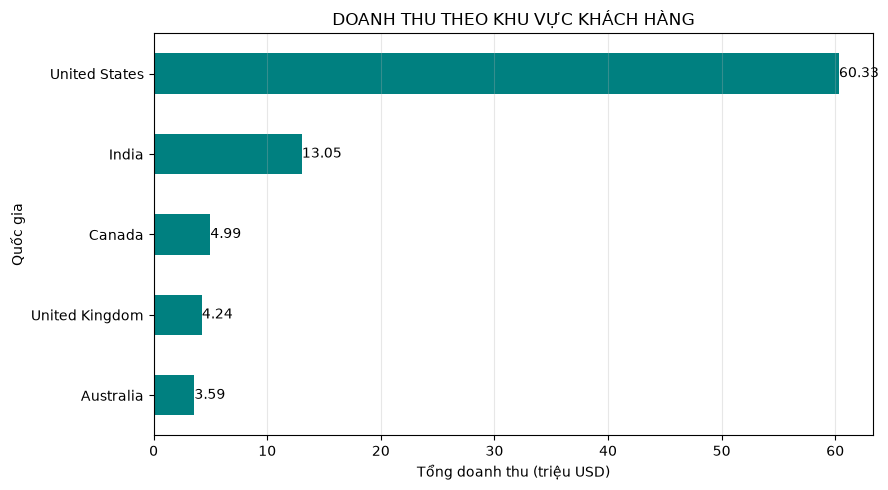

In [91]:
# Vẽ biểu đồ doanh thu theo khu vực khách hàng
data = doanh_thu_khu_vuc.sort_values() / 1_000_000

ax = data.plot(
    kind="barh",
    color="teal",
    figsize=(9, 5)
)

# Hiển thị số liệu (triệu USD)
for i, value in enumerate(data):
    ax.text(value, i, f"{value:,.2f}", va="center")

plt.title("DOANH THU THEO KHU VỰC KHÁCH HÀNG")
plt.xlabel("Tổng doanh thu (triệu USD)")
plt.ylabel("Quốc gia")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### CÂU HỎI 6: TỈ LỆ HỦY VÀ TRẢ HÀNG THEO NHÓM SẢN PHẨM

- **Thành viên phụ trách:** Hoàng Ngọc Tú
- **Mục tiêu:** Đo lường, phân tích và trực quan hóa tỉ lệ đơn hàng Cancelled và Returned theo 6 nhóm sản phẩm.

### 1. Khai báo thư viện và cấu hình hiển thị

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# Thiết lập hiển thị biểu đồ inline
%matplotlib inline

# Sử dụng font mặc định có sẵn của Colab (DejaVu Sans) để tránh lỗi thiếu font trên máy ảo Linux
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# Bỏ qua các cảnh báo không cần thiết về font chữ
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

### 2. Đọc dữ liệu và tính toán chỉ số (KPIs)

In [69]:
# Đọc trực tiếp dữ liệu từ link Google Drive được cung cấp trong ghi chú

# Tính toán số lượng đơn bằng crosstab
ct = pd.crosstab(df['Category'], df['OrderStatus'])
total_orders = ct.sum(axis=1)

# Tính toán tỉ lệ phần trăm
summary = pd.DataFrame({
    'Total_Orders': total_orders,
    'Cancelled_Orders': ct['Cancelled'],
    'Cancel_Rate_%': (ct['Cancelled'] / total_orders * 100).round(2),
    'Returned_Orders': ct['Returned'],
    'Return_Rate_%': (ct['Returned'] / total_orders * 100).round(2),
})

# Tổng tỉ lệ sự cố (Hủy + Trả)
summary['Total_Problem_%'] = (summary['Cancel_Rate_%'] + summary['Return_Rate_%']).round(2)

# Sắp xếp theo tổng tỉ lệ sự cố giảm dần
summary = summary.sort_values(by='Total_Problem_%', ascending=False).reset_index()

# Mức bình quân toàn sàn
avg_cancel = (df['OrderStatus'] == 'Cancelled').mean() * 100
avg_return = (df['OrderStatus'] == 'Returned').mean() * 100
avg_problem = avg_cancel + avg_return

print(f"Mức bình quân toàn sàn: Hủy = {avg_cancel:.2f}% | Trả = {avg_return:.2f}% | Tổng sự cố = {avg_problem:.2f}%")
display(summary)

Mức bình quân toàn sàn: Hủy = 3.03% | Trả = 3.05% | Tổng sự cố = 6.08%


,Category,Total_Orders,Cancelled_Orders,Cancel_Rate_%,Returned_Orders,Return_Rate_%,Total_Problem_%
0,Home & Kitchen,16610,508,3.06,534,3.21,6.27
1,Books,16752,500,2.98,523,3.12,6.10
2,Toys & Games,16542,512,3.10,495,2.99,6.09
3,Electronics,16853,544,3.23,475,2.82,6.05
4,Sports & Outdoors,16804,497,2.96,518,3.08,6.04
5,Clothing,16439,467,2.84,504,3.07,5.91


### 3. Vẽ biểu đồ


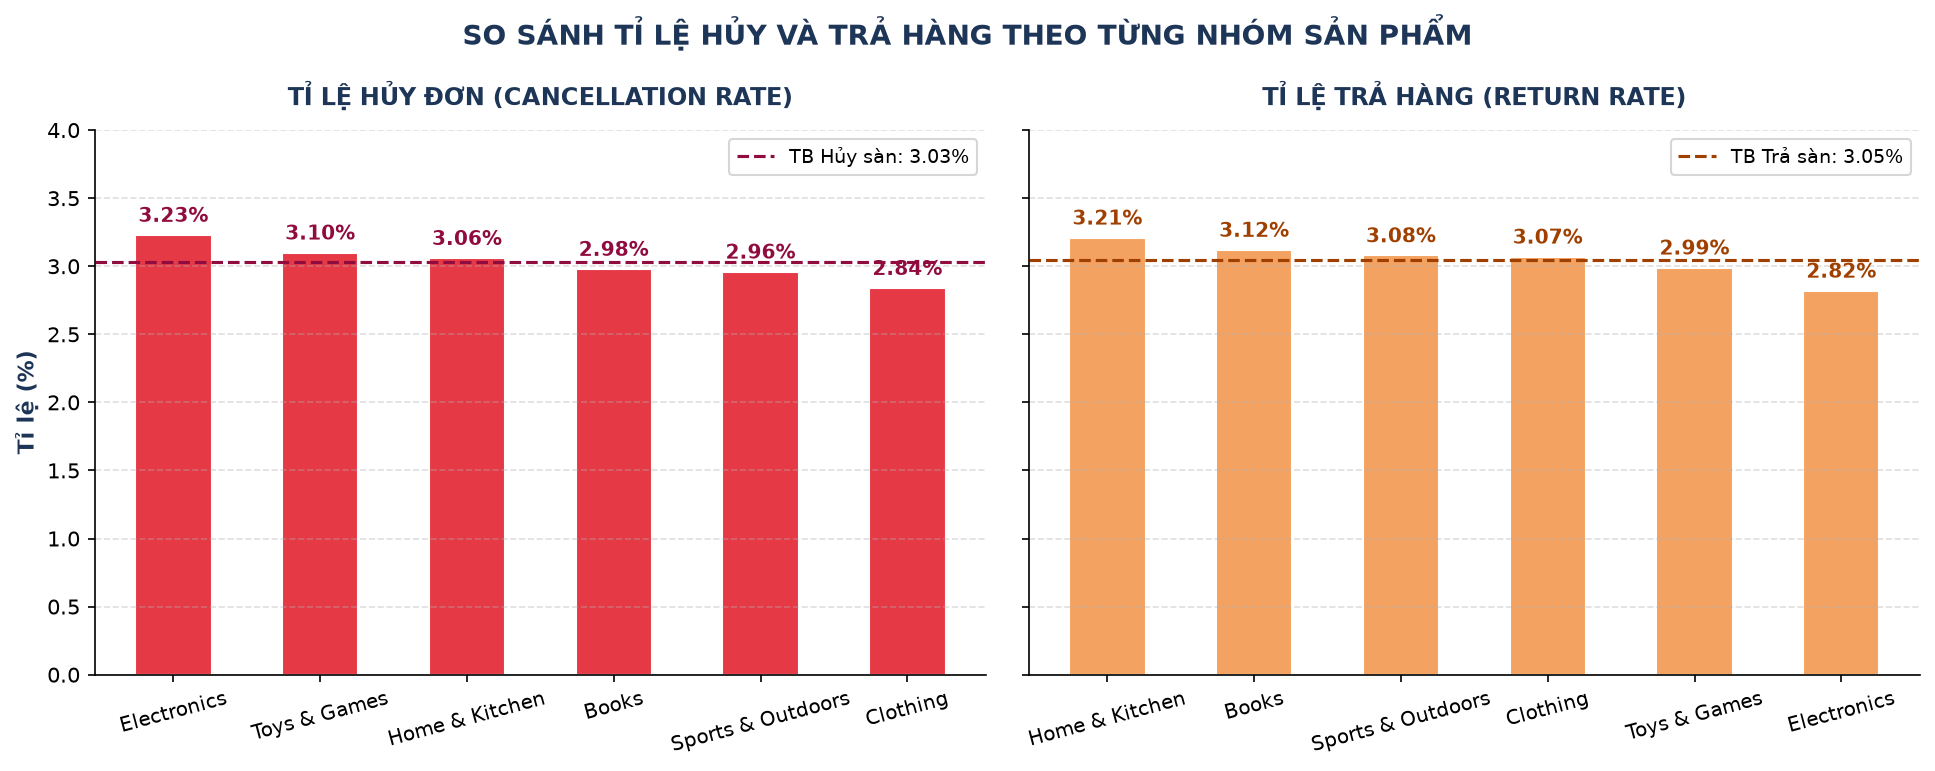

In [70]:
# Tạo hình chứa 2 biểu đồ con đặt cạnh nhau (Subplots 1x2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150, sharey=True)

# Sắp xếp riêng cho từng biểu đồ để làm nổi bật thứ hạng
df_cancel = summary.sort_values(by='Cancel_Rate_%', ascending=False)
df_return = summary.sort_values(by='Return_Rate_%', ascending=False)

# ==========================================
# BIỂU ĐỒ TRÁI: TỈ LỆ HỦY ĐƠN (CANCELLATION)
# ==========================================
bars1 = ax1.bar(df_cancel['Category'], df_cancel['Cancel_Rate_%'], color='#E63946', width=0.52, edgecolor='white')
ax1.axhline(avg_cancel, color='#900C3F', linestyle='--', linewidth=1.5, label=f'TB Hủy sàn: {avg_cancel:.2f}%')

for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f'{h:.2f}%', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#900C3F')

ax1.set_title('TỈ LỆ HỦY ĐƠN (CANCELLATION RATE)', fontsize=11.5, fontweight='bold', pad=12, color='#1D3557')
ax1.set_ylabel('Tỉ lệ (%)', fontsize=10.5, fontweight='bold', color='#1D3557')
ax1.set_ylim(0, 4.0)
ax1.tick_params(axis='x', rotation=15, labelsize=9.5)
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.legend(loc='upper right', fontsize=9, frameon=True)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ==========================================
# BIỂU ĐỒ PHẢI: TỈ LỆ TRẢ HÀNG (RETURN)
# ==========================================
bars2 = ax2.bar(df_return['Category'], df_return['Return_Rate_%'], color='#F4A261', width=0.52, edgecolor='white')
ax2.axhline(avg_return, color='#A04000', linestyle='--', linewidth=1.5, label=f'TB Trả sàn: {avg_return:.2f}%')

for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f'{h:.2f}%', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#A04000')

ax2.set_title('TỈ LỆ TRẢ HÀNG (RETURN RATE)', fontsize=11.5, fontweight='bold', pad=12, color='#1D3557')
ax2.tick_params(axis='x', rotation=15, labelsize=9.5)
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', fontsize=9, frameon=True)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Tiêu đề chung cho cả 2 biểu đồ
fig.suptitle('SO SÁNH TỈ LỆ HỦY VÀ TRẢ HÀNG THEO TỪNG NHÓM SẢN PHẨM', fontsize=13.5, fontweight='bold', color='#1D3557', y=0.98)
plt.tight_layout()

# Lưu ảnh chất lượng cao 300 DPI để chèn vào slide
plt.savefig('cau_6_ti_le_huy_tra.png', dpi=300)
plt.show()

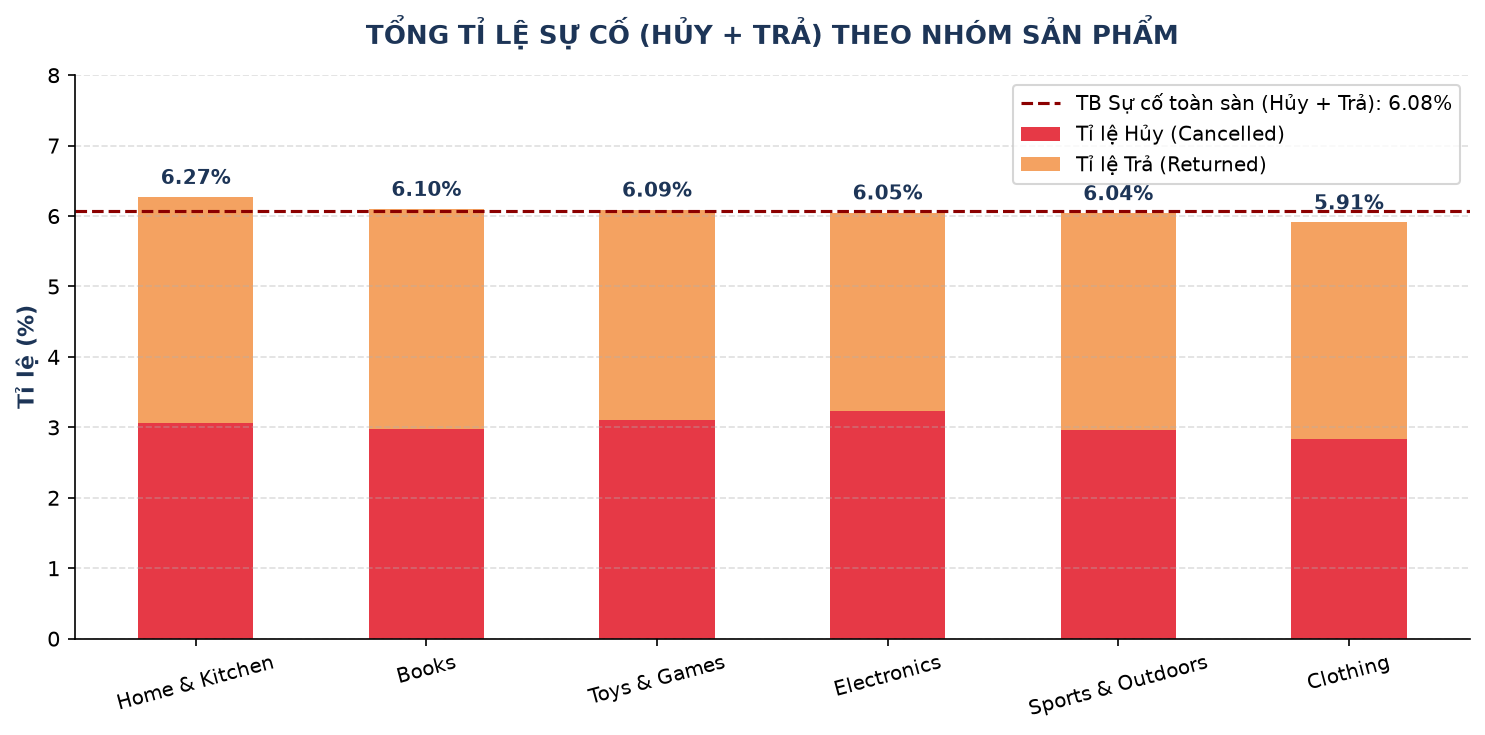

In [71]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

summary_stacked = summary.sort_values(by='Total_Problem_%', ascending=False).reset_index(drop=True)

# Vẽ cột chồng: Hủy ở dưới, Trả ở trên
bars_c = ax.bar(summary_stacked['Category'], summary_stacked['Cancel_Rate_%'], label='Tỉ lệ Hủy (Cancelled)', color='#E63946', width=0.5)
bars_r = ax.bar(summary_stacked['Category'], summary_stacked['Return_Rate_%'], bottom=summary_stacked['Cancel_Rate_%'], label='Tỉ lệ Trả (Returned)', color='#F4A261', width=0.5)

# Chỉ có DUY NHẤT 1 đường nét đứt: Mức sự cố bình quân sàn (6.08%)
ax.axhline(avg_problem, color='#8B0000', linestyle='--', linewidth=1.5, label=f'TB Sự cố toàn sàn (Hủy + Trả): {avg_problem:.2f}%')

# Nhãn tổng phần trăm trên đỉnh cột
for i, row in summary_stacked.iterrows():
    total_val = row['Total_Problem_%']
    ax.annotate(f'{total_val:.2f}%', xy=(i, total_val), xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1D3557')

ax.set_title('TỔNG TỈ LỆ SỰ CỐ (HỦY + TRẢ) THEO NHÓM SẢN PHẨM', fontsize=12.5, fontweight='bold', pad=15, color='#1D3557')
ax.set_ylabel('Tỉ lệ (%)', fontsize=10.5, fontweight='bold', color='#1D3557')
ax.set_ylim(0, 8.0)
ax.tick_params(axis='x', rotation=15, labelsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(loc='upper right', fontsize=9.5, frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Câu hỏi 7: Phí vận chuyển theo khu vực (State) và theo giá trị đơn hàng (TotalAmount)

Nguyễn Huỳnh Tuấn Khang

In [72]:
# Dữ liệu phân tích phí vận chuyển theo State
df_shipping = df[['ShippingCost', 'State', 'TotalAmount',
                  'OrderStatus']].copy()

# Dữ liệu phân tích doanh thu:
# Loại bỏ đơn Cancelled và Returned
df_revenue = df_shipping[
    ~df_shipping['OrderStatus'].isin(['Cancelled', 'Returned'])
].copy()

print('Tổng số đơn hàng:', len(df))
print('Số đơn được tính doanh thu:', len(df_revenue))
print('Số đơn không tính doanh thu:', len(df) - len(df_revenue))

Tổng số đơn hàng: 100000
Số đơn được tính doanh thu: 93923
Số đơn không tính doanh thu: 6077


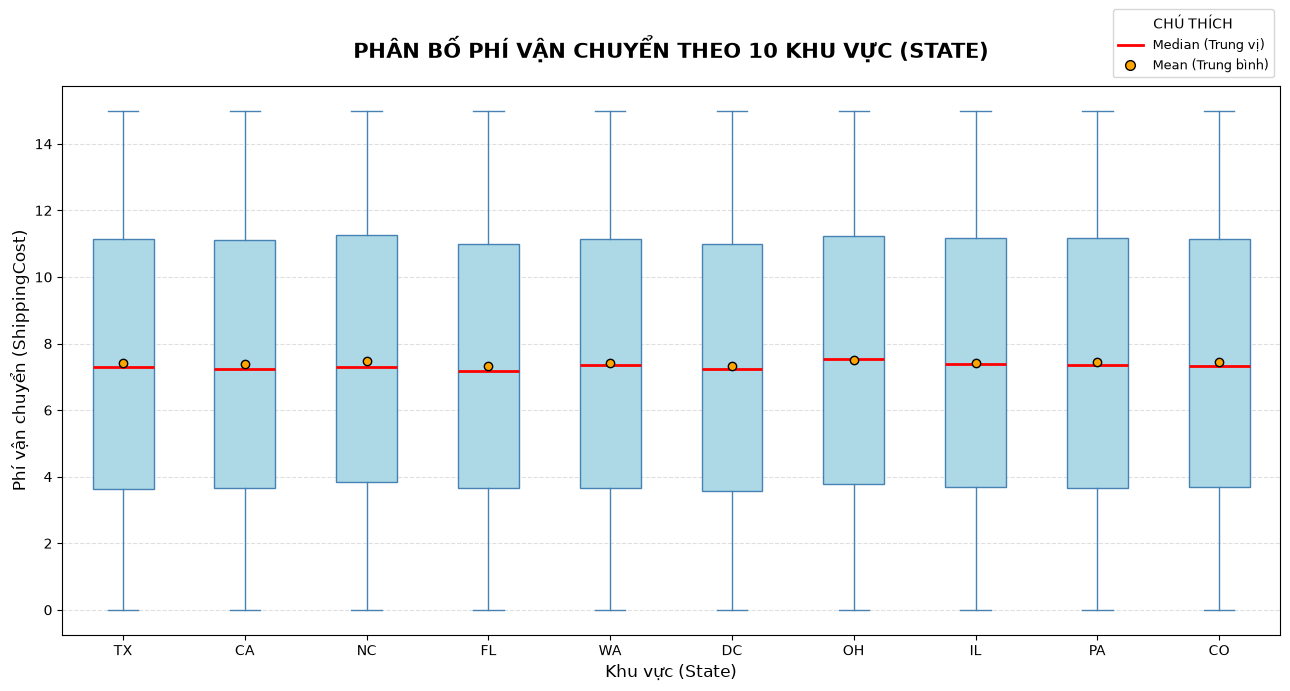

In [73]:
# Chọn 10 State có nhiều đơn hàng nhất
top_states = df_shipping['State'].value_counts().head(10).index

# Lọc dữ liệu theo 10 State
df_box = df_shipping[df_shipping['State'].isin(top_states)]

# Chuẩn bị dữ liệu cho Boxplot
data = [
    df_box[df_box['State'] == state]['ShippingCost']
    for state in top_states
]

# Vẽ biểu đồ
plt.figure(figsize=(13, 7))

plt.boxplot(
    data,
    tick_labels=top_states,
    patch_artist=True,
    showmeans=True,
    meanprops=dict(
        marker='o',
        markerfacecolor='orange',
        markeredgecolor='black',
        markersize=6
    ),
    medianprops=dict(color='red', linewidth=2),
    boxprops=dict(facecolor='lightblue', color='steelblue'),
    whiskerprops=dict(color='steelblue'),
    capprops=dict(color='steelblue')
)

plt.title(
    'PHÂN BỐ PHÍ VẬN CHUYỂN THEO 10 KHU VỰC (STATE)',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.xlabel('Khu vực (State)', fontsize=12)
plt.ylabel('Phí vận chuyển (ShippingCost)', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

# Chú thích
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color='red', linewidth=2,
           label='Median (Trung vị)'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='orange',
           markeredgecolor='black',
           markersize=7,
           label='Mean (Trung bình)')
]

plt.legend(
    handles=legend_elements,
    loc='upper right',
    bbox_to_anchor=(1, 1.15),
    title='CHÚ THÍCH',
    fontsize=9
)

plt.tight_layout()
plt.show()

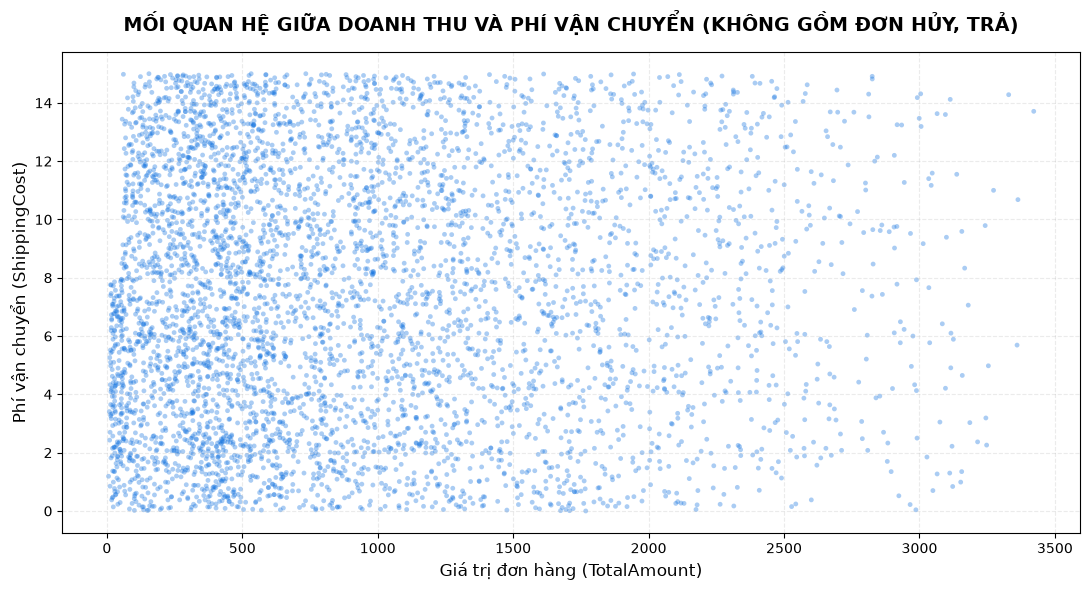

In [74]:
# Lấy dữ liệu đã loại đơn hủy và trả
df_scatter = df_revenue.copy()

# Lấy mẫu tối đa 5.000 đơn để biểu đồ dễ quan sát
df_sample = df_scatter.sample(
    n=min(5000, len(df_scatter)),
    random_state=42
)

plt.figure(figsize=(11, 6))

plt.scatter(
    df_sample['TotalAmount'],
    df_sample['ShippingCost'],
    s=12,
    alpha=0.35,
    color="#0C6FDF",
    edgecolors='none'
)

plt.title(
    'MỐI QUAN HỆ GIỮA DOANH THU VÀ PHÍ VẬN CHUYỂN '
    '(KHÔNG GỒM ĐƠN HỦY, TRẢ)',
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.xlabel('Giá trị đơn hàng (TotalAmount)', fontsize=12)
plt.ylabel('Phí vận chuyển (ShippingCost)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

In [75]:
# Thống kê phí vận chuyển theo từng State
shipping_by_state = df_shipping.groupby('State')['ShippingCost'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

# Sắp xếp theo phí vận chuyển trung bình giảm dần
shipping_by_state = shipping_by_state.sort_values(
    by='mean',
    ascending=False
)

# Đổi tên cột sang tiếng Việt
shipping_by_state.columns = [
    'Số đơn hàng',
    'Phí vận chuyển trung bình',
    'Phí vận chuyển trung vị',
    'Phí thấp nhất',
    'Phí cao nhất'
]

print(shipping_by_state.round(2))

       Số đơn hàng  Phí vận chuyển trung bình  Phí vận chuyển trung vị  \
State                                                                    
OH            5021                       7.50                     7.53   
NY            4949                       7.50                     7.38   
NC            5110                       7.46                     7.30   
CO            4991                       7.43                     7.34   
PA            5014                       7.43                     7.36   
IL            5020                       7.42                     7.38   
WA            5039                       7.41                     7.35   
AZ            4941                       7.41                     7.27   
TX           24896                       7.40                     7.30   
CA           19921                       7.38                     7.25   
IN            4970                       7.37                     7.17   
DC            5021                    

In [76]:
# Tính hệ số tương quan giữa giá trị đơn hàng
# và phí vận chuyển (loại đơn hủy, trả)
correlation = df_revenue['TotalAmount'].corr(
    df_revenue['ShippingCost']
)

print('Hệ số tương quan:', round(correlation, 4))

# Đánh giá mức độ tương quan
if correlation > 0:
    print('Hai biến có tương quan thuận.')
elif correlation < 0:
    print('Hai biến có tương quan nghịch.')
else:
    print('Hai biến không có tương quan tuyến tính.')

Hệ số tương quan: 0.0398
Hai biến có tương quan thuận.


### Câu 8: Hình thức thanh toán và tỉ lệ hủy, trả hàng theo hình thức thanh toán

Trương Hoàng Nguyên

                  Tổng đơn  Tỉ lệ hủy  Tỉ lệ trả
PaymentMethod                                   
Credit Card          35038       3.09       3.07
Debit Card           20024       2.96       3.04
UPI                  15066       2.95       2.90
Amazon Pay           15017       3.07       3.14
Net Banking           9927       2.93       3.15
Cash on Delivery      4928       3.17       2.90
p = 0.777


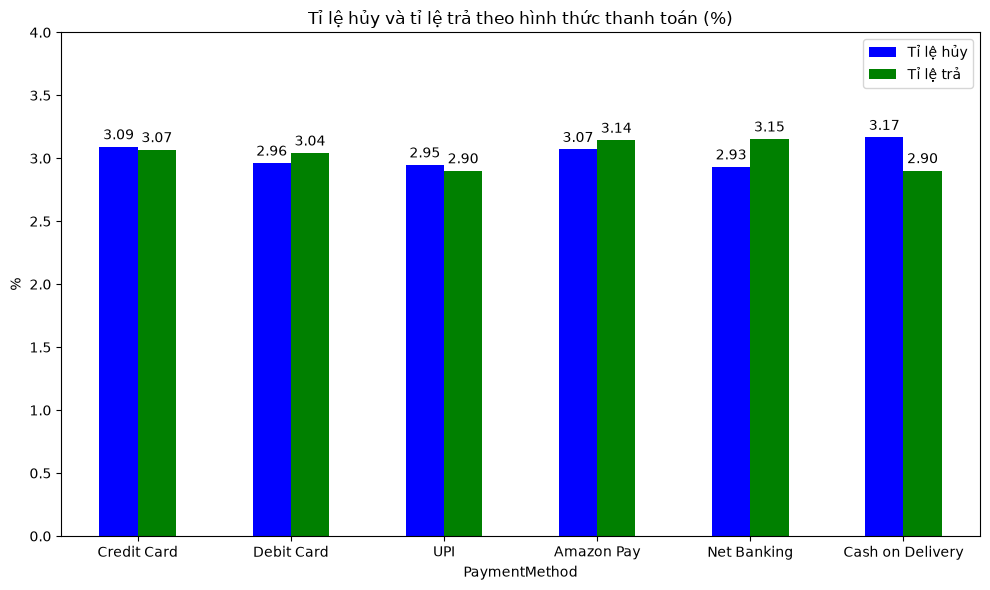

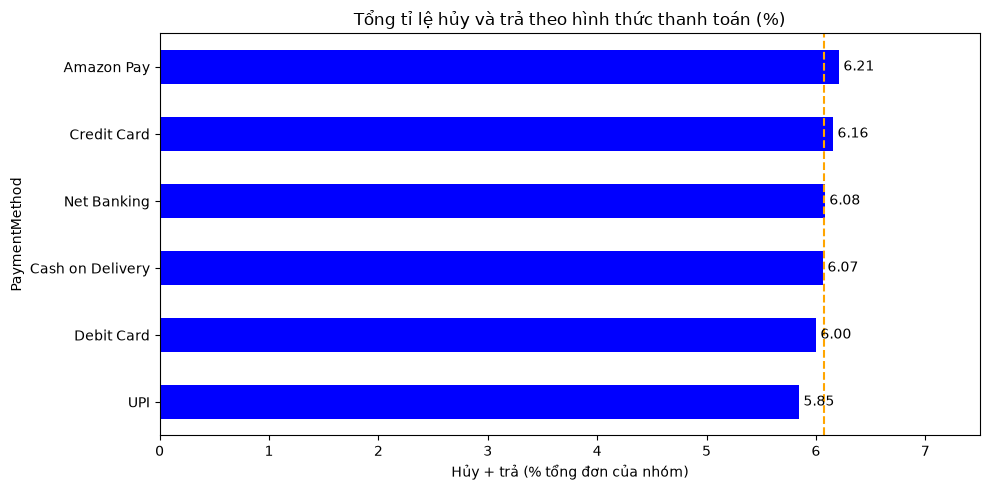

In [77]:
#Câu 8:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency


# 1. Đếm số đơn của từng hình thức thanh toán
tong_don = df.groupby("PaymentMethod").size()

# 2. Đếm đơn hủy và đơn trả
don_huy = df[df["OrderStatus"] == "Cancelled"].groupby("PaymentMethod").size()
don_tra = df[df["OrderStatus"] == "Returned"].groupby("PaymentMethod").size()

# 3. Tính tỉ lệ(%)
bang = pd.DataFrame({
    "Tổng đơn": tong_don,
    "Tỉ lệ hủy": don_huy / tong_don * 100,
    "Tỉ lệ trả": don_tra / tong_don * 100,
    })
bang = bang.sort_values("Tổng đơn", ascending=False)
print(bang.round(2))

# 4. Kiểm tra xem khác biệt có ý nghĩa không
p = chi2_contingency(pd.crosstab(df["PaymentMethod"], df["OrderStatus"]))[1]
print("p =", round(p, 3))

# 5. Vẽ biểu đồ cột nhóm
ax= bang[["Tỉ lệ hủy", "Tỉ lệ trả"]].plot(kind="bar", color=["blue", "green"], figsize=(10, 6))
for cot in ax.containers:
    ax.bar_label(cot, fmt="%.2f", padding=3)
plt.title("Tỉ lệ hủy và tỉ lệ trả theo hình thức thanh toán (%)")
plt.ylabel("%")
plt.ylim(0, 4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("cau8_bieu_do.png", dpi=200)
plt.show()

# 6. Biểu đồ tổng tỉ lệ hủy + trả (thanh ngang)
bang["Hủy + trả"] = bang["Tỉ lệ hủy"] + bang["Tỉ lệ trả"]
du_lieu = bang["Hủy + trả"].sort_values()
ax = du_lieu.plot.barh(color="blue", figsize=(10, 5))
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
mask = df["OrderStatus"].isin(["Cancelled", "Returned"])
chung = mask.mean() * 100
plt.axvline(chung, color="orange", linestyle="--")
plt.title("Tổng tỉ lệ hủy và trả theo hình thức thanh toán (%)")
plt.xlabel("Hủy + trả (% tổng đơn của nhóm)")
plt.xlim(0, 7.5)
plt.tight_layout()
plt.savefig("cau8_bieu_do_2.png", dpi=200)
plt.show()

### Câu 9: Top 5 sản phẩm có tỉ lệ trả hàng cao nhất

Huỳnh Gia Huy

In [78]:
#CÂU HỎI 9:
print(df['OrderStatus'].value_counts())
print()

order_per_product = (df.groupby('ProductName')['OrderID'].nunique())

print(order_per_product.sum())
print()
print(order_per_product.describe())

OrderStatus
Delivered    74628
Shipped      15192
Pending       4103
Returned      3049
Cancelled     3028
Name: count, dtype: int64

100000

count      50.00000
mean     2000.00000
std        43.13103
min      1910.00000
25%      1970.50000
50%      2006.50000
75%      2030.75000
max      2098.00000
Name: OrderID, dtype: float64


In [79]:
#mean cua trang thai Returned
a= 3049/100000
print(a)

df['IsReturned'] = df['OrderStatus'] == 'Returned'
df['IsReturned'].mean()

0.03049


np.float64(0.03049)

In [80]:
#Bảng stat truc quan
df['IsReturned'] = df['OrderStatus'] == 'Returned'

#stat top 5 tra hang
stats = (df.groupby('ProductName').agg(TotalOrders=('OrderID', 'count'), ReturnRate=('IsReturned', 'mean')).sort_values('ReturnRate', ascending=False).head(5))

stats['ReturnRate'] = (stats['ReturnRate'] * 100).round(2)  # đổi sang %
print(stats)

                             TotalOrders  ReturnRate
ProductName                                         
Yoga Mat                            2041        3.97
Noise Cancelling Headphones         2031        3.79
Dress Shirt                         2007        3.59
Cookware Set                        2058        3.55
Webcam Full HD                      2013        3.53


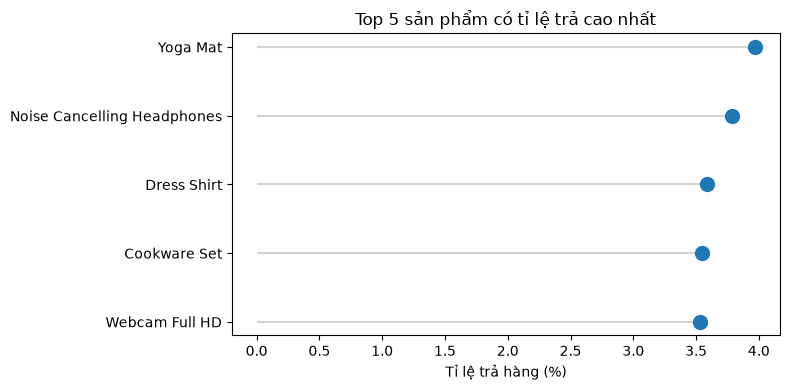

In [81]:
# Dot plot (đảo thứ tự để sản phẩm cao nhất nằm trên cùng)
s = stats.iloc[::-1]
plt.figure(figsize=(8, 4))
plt.hlines(s.index, 0, s['ReturnRate'], color='lightgray')
plt.plot(s['ReturnRate'], s.index, 'o', markersize=10)
plt.xlabel('Tỉ lệ trả hàng (%)')
plt.title(f'Top 5 sản phẩm có tỉ lệ trả cao nhất')
plt.tight_layout()

plt.show()

### Câu mở rộng: Trả hàng phụ thuộc vào giảm giá hay không?

Huỳnh Gia Huy

             Orders  Return%
DiscountBin                 
0%            40246     3.12
≤10%          34799     2.99
10-20%        17980     2.92
20-30%         6975     3.28


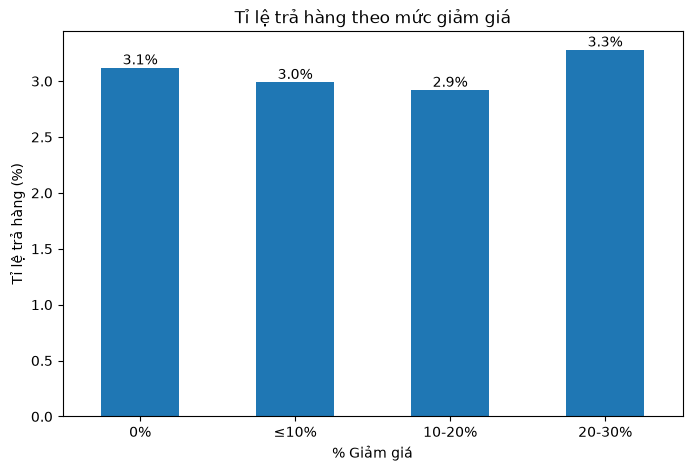

In [82]:
df['DiscountBin'] = pd.cut(
    df['Discount'],
    bins=[-0.001, 0, 0.1, 0.2, 1],
    labels=['0%', '≤10%', '10-20%', '20-30%']
)

# 2. Bảng tổng hợp (chỉ Returned)
g = df.groupby('DiscountBin', observed=True)['OrderStatus']
t = pd.DataFrame({
    'Orders':  g.size(),
    'Return%': g.apply(lambda s: (s == 'Returned').mean() * 100),
}).round(2)
print(t)

# 3. Biểu đồ cột
ax = t['Return%'].plot(kind='bar', figsize=(8, 5), rot=0)
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.ylabel('Tỉ lệ trả hàng (%)')
plt.xlabel('% Giảm giá')
plt.title('Tỉ lệ trả hàng theo mức giảm giá')
plt.show()

Kết quả:
Yoga Mat có tỉ lệ trả cao nhất (3,97%, tức khoảng 81 trên 2041 đơn), tiếp theo là Noise Cancelling Headphones (3,79%), Dress Shirt (3,59%), Cookware Set (3,55%) và Webcam Full HD (3,53%).

Chênh lệch nhỏ: Cả 5 sản phẩm chỉ dao động trong khoảng 3,5% đến 4,0%, trong khi mức trung bình toàn bộ dữ liệu là khoảng 3,05%. Nghĩa là top 5 chỉ cao hơn trung bình khoảng 0,5 đến 0,9 điểm phần trăm.

Không có sản phẩm “xấu” rõ rệt: Các sản phẩm thuộc nhiều nhóm khác nhau (đồ thể thao, điện tử, quần áo, đồ gia dụng), nên không có nhóm ngành nào nổi bật về trả hàng.

Ý nghĩa ngưỡng: Mọi sản phẩm đều có hơn 1900 đơn nên tỉ lệ khá ổn định, không bị méo bởi mẫu nhỏ.

### Câu 10: Dashboard tổng quan Amazon Sales

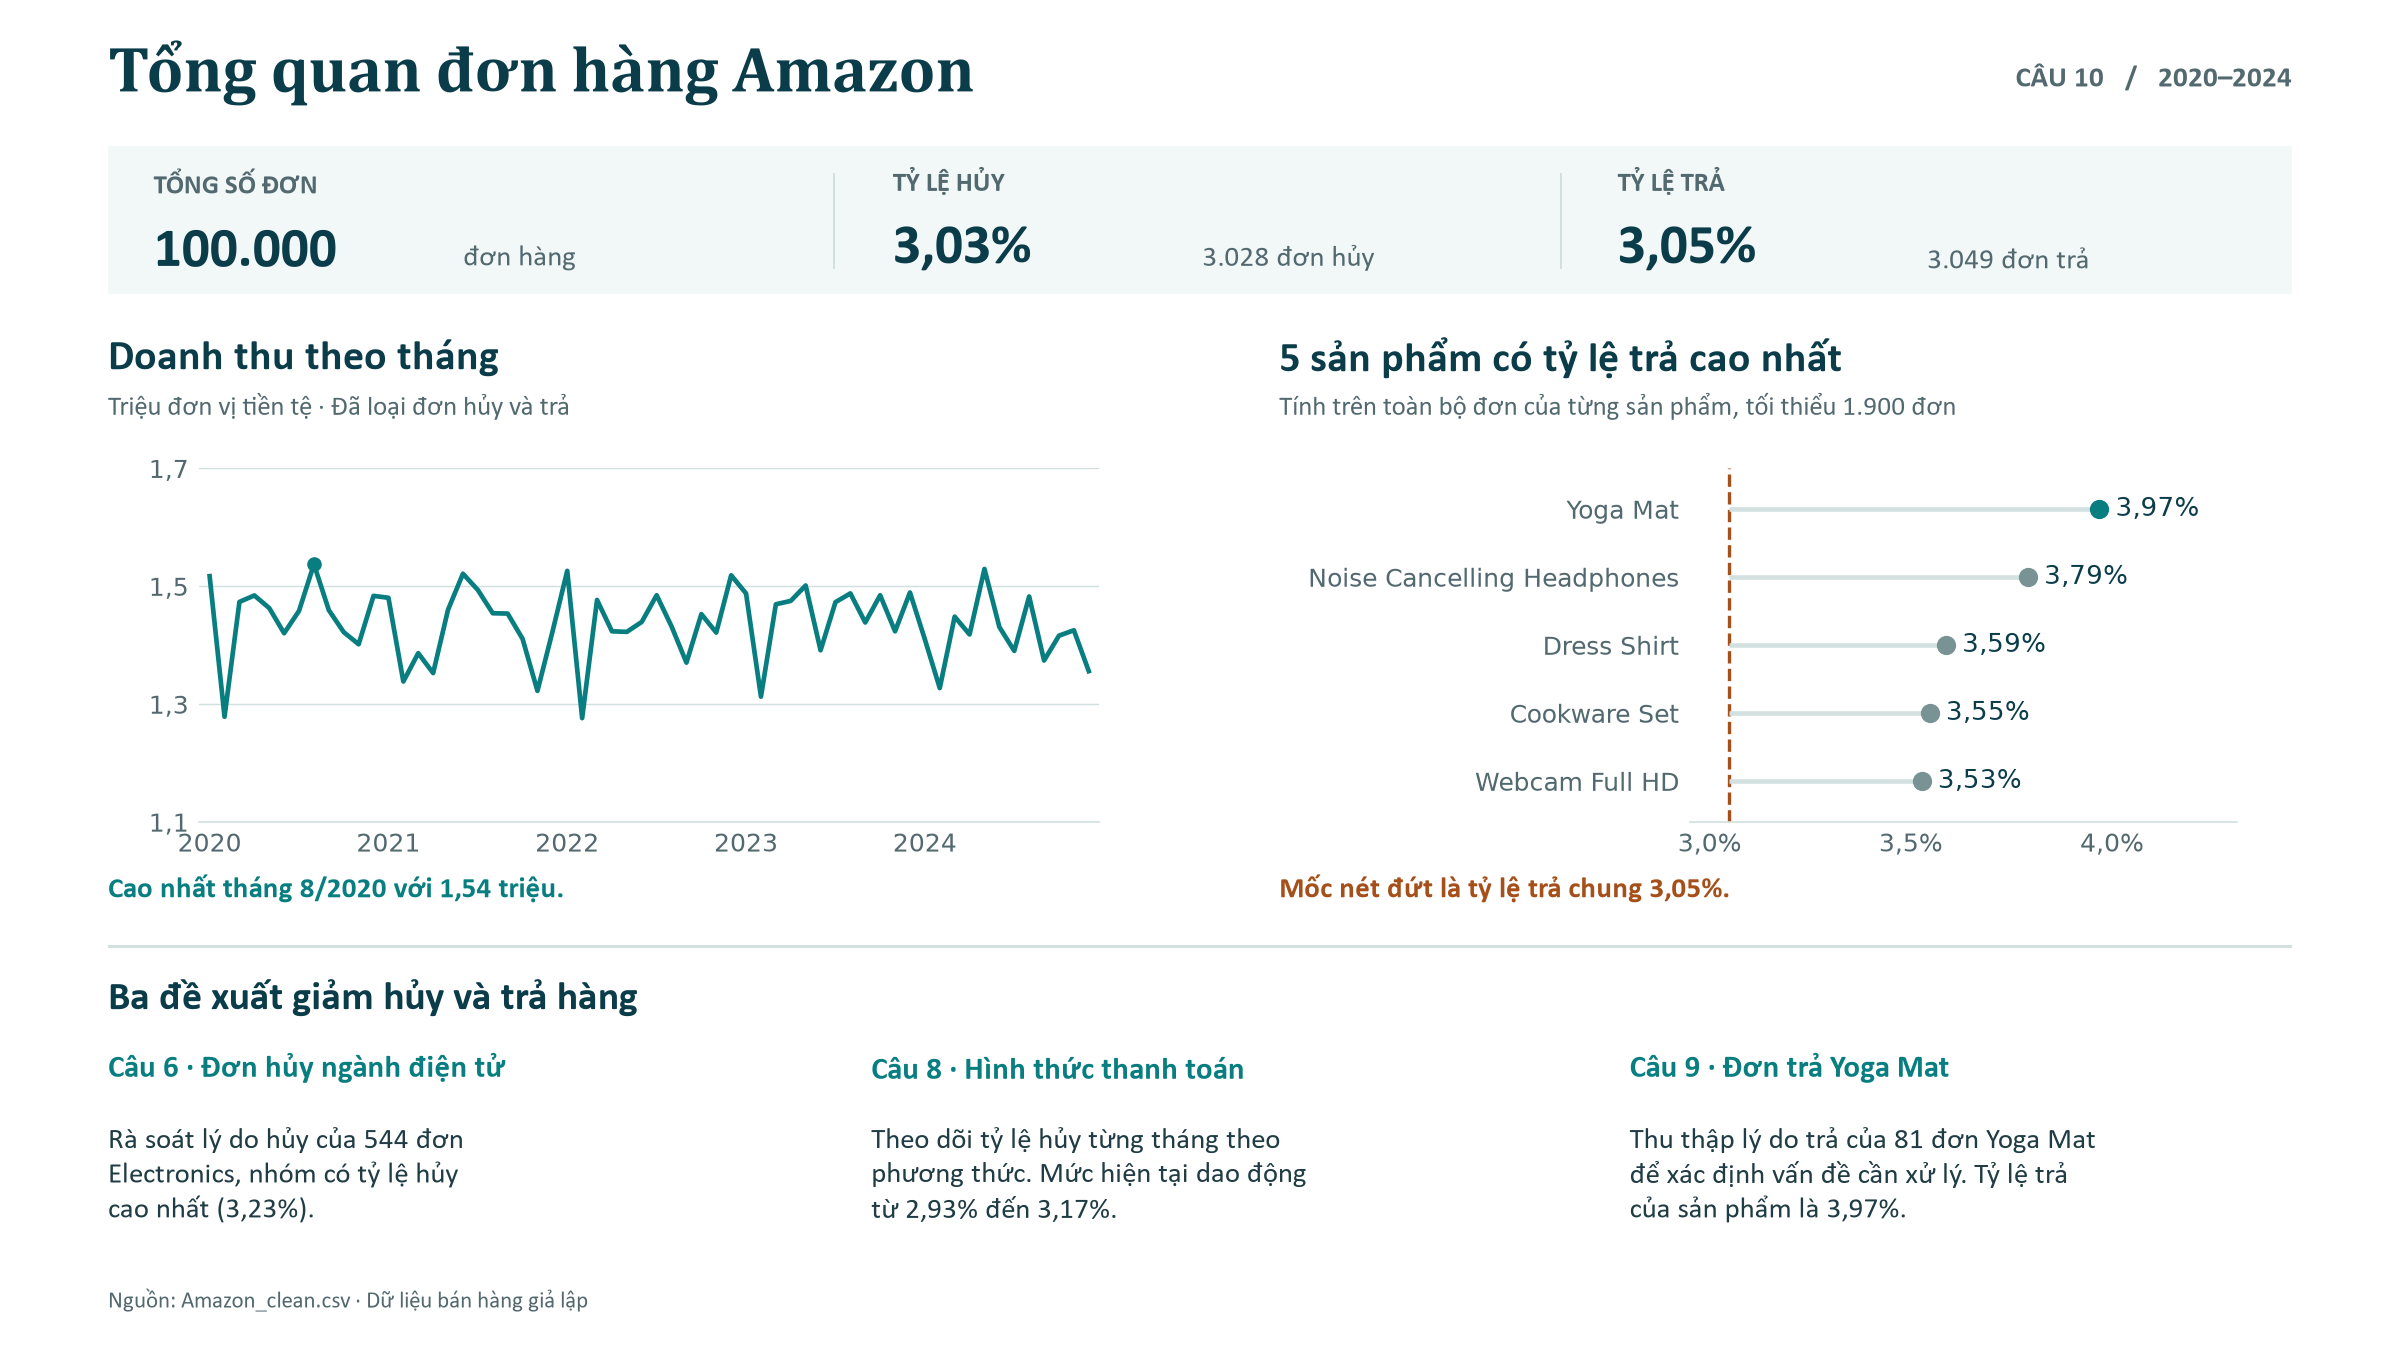